# 信用卡欺诈交易预测

## 0. 业务问题
用交易的 V1–V28、金额和时段特征，预测这笔交易是否为欺诈（Class=1）。目标是在尽量识别更多欺诈交易、减少资金损失的同时，控制正常交易被误判和拦截的比例，避免影响持卡人体验和银行客户关系。

- **漏掉欺诈（FN，对应召回率）**：银行或持卡人可能遭受直接资金损失，还会产生赔付、调查和风控成本。
- **误判正常交易（FP，对应精确率）**：持卡人的正常付款被拒绝，会带来不满、投诉和交易流失，甚至降低对银行的信任。

**取舍**：漏掉欺诈的代价更大，所以优先保证召回率，同时把误报量控制在审核团队能处理的范围内。误判不一定等于拒绝交易，也可以分级处理（拒绝、验证、放行）。

## 1. 数据口径

| # | 项目 | 口径 |
|---|---|---|
| 1 | 样本单位 | 一行是一笔交易。数据中没有卡号或用户 ID，只做交易级预测 |
| 2 | 标签 | Class=1 表示事后确认的欺诈 |
| 3 | 欺诈率 | 按笔数计算为主，按金额计算作为补充（诈骗无大小，小额欺诈可能升级） |
| 4 | 去重 | 删除完全重复的行，避免同一笔交易同时出现在训练集和测试集（数据泄漏） |
| 5 | 0 元交易 | 保留，可能是试卡或预授权，属于风险信号 |
| 6 | 时间 | Time 是相对秒数，换算成相对小时 `(Time // 3600) % 24`。**起点未知，第 2 小时不等于凌晨 2 点** |
| 7 | 切分 | 按 Time 排序后，前 70% 作为训练集，后 30% 作为测试集（用过去预测未来） |

数据来源：公开的信用卡欺诈数据集（约 48 小时的交易，规模和字段与 Kaggle 上的「Credit Card Fraud Detection」数据集一致），放在 `data/creditcardfraud.csv`，不上传到 GitHub。

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             average_precision_score, roc_auc_score, confusion_matrix)

RANDOM_STATE = 42

## 2. 读取与清洗

In [2]:
raw = pd.read_csv("data/creditcardfraud.csv")
print("原始：", raw.shape, "缺失值总数：", raw.isna().sum().sum())

dup_mask = raw.duplicated()
print("重复行：", dup_mask.sum(), "其中欺诈：", raw.loc[dup_mask, "Class"].sum())

df = raw.drop_duplicates().reset_index(drop=True)
df["hour"] = (df["Time"] // 3600) % 24
print("去重后：", df.shape, "欺诈笔数：", df["Class"].sum(), f"欺诈率：{df['Class'].mean():.4%}")

原始： (284807, 31) 缺失值总数： 0


重复行： 1081 其中欺诈： 19


去重后： (283726, 32) 欺诈笔数： 473 欺诈率：0.1667%


## 3. 探索性分析（EDA）

In [3]:
# 欺诈率：笔数口径（主）和金额口径（补充）
by_count = df["Class"].mean()
by_amount = df.loc[df["Class"] == 1, "Amount"].sum() / df["Amount"].sum()
print(f"按笔数：{by_count:.4%}    按金额：{by_amount:.4%}")

# 金额分布
print(df.groupby("Class")["Amount"].describe(percentiles=[.5, .9, .99]).T.round(2))

# 0 元交易
zero = df[df["Amount"] == 0]
print(f"0 元交易：{len(zero)} 笔，其中欺诈 {zero['Class'].sum()} 笔，欺诈率 {zero['Class'].mean():.2%}")

按笔数：0.1667%    按金额：0.2334%
Class          0        1
count  283253.00   473.00
mean       88.41   123.87
std       250.38   260.21
min         0.00     0.00
50%        22.00     9.82
90%       203.00   348.65
99%      1018.06  1364.14
max     25691.16  2125.87
0 元交易：1808 笔，其中欺诈 25 笔，欺诈率 1.38%


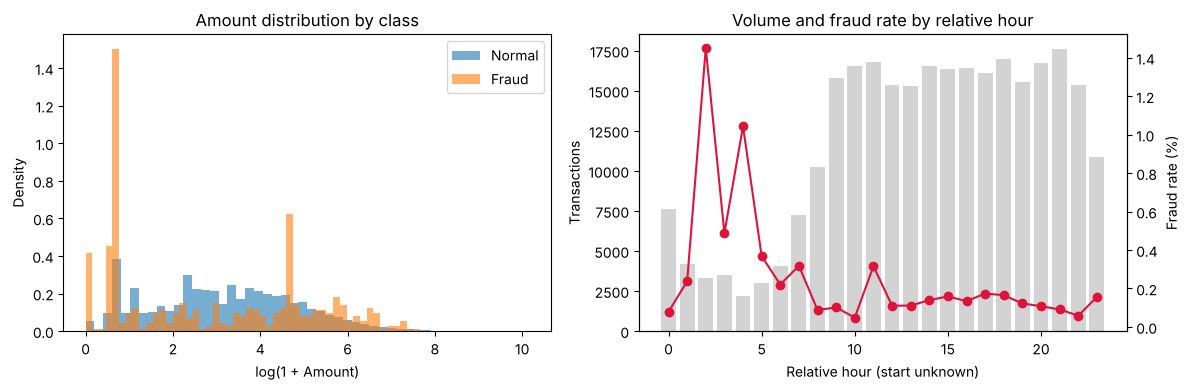

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# 金额分布（对数坐标，按类别）
for c, label in [(0, "Normal"), (1, "Fraud")]:
    axes[0].hist(np.log1p(df.loc[df["Class"] == c, "Amount"]), bins=50,
                 density=True, alpha=0.6, label=label)
axes[0].set_xlabel("log(1 + Amount)")
axes[0].set_ylabel("Density")
axes[0].set_title("Amount distribution by class")
axes[0].legend()

# 相对小时的欺诈率与交易量
hourly = df.groupby("hour")["Class"].agg(["mean", "size"])
axes[1].bar(hourly.index, hourly["size"], color="lightgray", label="Transactions")
ax2 = axes[1].twinx()
ax2.plot(hourly.index, hourly["mean"] * 100, color="crimson", marker="o", label="Fraud rate (%)")
axes[1].set_xlabel("Relative hour (start unknown)")
axes[1].set_ylabel("Transactions")
ax2.set_ylabel("Fraud rate (%)")
axes[1].set_title("Volume and fraud rate by relative hour")
plt.tight_layout()
plt.show()

## 4. 按时间切分训练集和测试集

In [5]:
df = df.sort_values("Time").reset_index(drop=True)
FEATURES = [f"V{i}" for i in range(1, 29)] + ["Amount", "hour"]
TARGET = "Class"

cut = int(len(df) * 0.7)
train, test = df.iloc[:cut], df.iloc[cut:]
X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

for name, part in [("训练集", train), ("测试集", test)]:
    print(f"{name}：{len(part):>7} 笔，欺诈 {part[TARGET].sum():>3} 笔，欺诈率 {part[TARGET].mean():.4%}，"
          f"时间 {part['Time'].min()/3600:.1f}–{part['Time'].max()/3600:.1f} 小时")

训练集： 198608 笔，欺诈 366 笔，欺诈率 0.1843%，时间 0.0–36.9 小时
测试集：  85118 笔，欺诈 107 笔，欺诈率 0.1257%，时间 36.9–48.0 小时


测试期的欺诈率低于训练期，这是**欺诈率随时间波动（分布漂移）**的表现，不是切分出错。随机切分会把这种波动抹平，让评估偏乐观。

## 5. 基线：为什么准确率会骗人

In [6]:
def evaluate(name, y_true, y_pred, y_score=None):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    row = {
        "模型": name,
        "准确率": accuracy_score(y_true, y_pred),
        "精确率": precision_score(y_true, y_pred, zero_division=0),
        "召回率": recall_score(y_true, y_pred),
        "PR-AUC": average_precision_score(y_true, y_score) if y_score is not None else np.nan,
        "ROC-AUC": roc_auc_score(y_true, y_score) if y_score is not None else np.nan,
        "抓到欺诈 TP": tp, "漏掉欺诈 FN": fn, "误判正常 FP": fp,
    }
    return row

results = []

# 基线 1：全猜正常
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
results.append(evaluate("全猜正常", y_test, dummy.predict(X_test)))

# 基线 2：逻辑回归（不做任何不平衡处理，阈值 0.5）
logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
logreg.fit(X_train, y_train)
results.append(evaluate("逻辑回归（未处理不平衡）", y_test,
                        logreg.predict(X_test), logreg.predict_proba(X_test)[:, 1]))

pd.DataFrame(results).set_index("模型").round(4)

,准确率,精确率,召回率,PR-AUC,ROC-AUC,抓到欺诈 TP,漏掉欺诈 FN,误判正常 FP
模型,,,,,,,,
全猜正常,0.9987,0.0000,0.000,NaN,NaN,0,107,0
逻辑回归（未处理不平衡）,0.9991,0.7143,0.514,0.7019,0.9749,55,52,22


### 待你判断
1. 「全猜正常」的准确率和逻辑回归几乎一样高，召回率却差很多。这说明准确率在这里能不能用来比较模型？
2. 逻辑回归漏掉的那些欺诈，对应的业务代价是什么？下一步用 class_weight 处理不平衡后，你预期召回率和精确率会怎么变化？

## 6. 处理不平衡：class_weight

训练集里每 1 笔欺诈，大约对应 542 笔正常交易。模型为了让整体错误最少，会倾向于「宁可都猜正常」。

`class_weight="balanced"` 的意思是：训练时**猜错一笔欺诈的惩罚，约等于猜错 542 笔正常交易**。这样模型会更愿意把可疑交易判为欺诈，代价是误判正常交易的数量会增加。

In [7]:
logreg_bal = make_pipeline(StandardScaler(),
                           LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE))
logreg_bal.fit(X_train, y_train)
results.append(evaluate("逻辑回归（class_weight）", y_test,
                        logreg_bal.predict(X_test), logreg_bal.predict_proba(X_test)[:, 1]))

pd.DataFrame(results).set_index("模型").round(4)

,准确率,精确率,召回率,PR-AUC,ROC-AUC,抓到欺诈 TP,漏掉欺诈 FN,误判正常 FP
模型,,,,,,,,
全猜正常,0.9987,0.0000,0.0000,NaN,NaN,0,107,0
逻辑回归（未处理不平衡）,0.9991,0.7143,0.5140,0.7019,0.9749,55,52,22
逻辑回归（class_weight）,0.9567,0.0257,0.9065,0.7758,0.9802,97,10,3678


### 待你判断
1. 召回率大幅上升，但误判正常交易从 22 笔增加到 3,678 笔。按你「拒绝、验证、放行」的思路，这 3,678 笔误判如果走短信验证，你能接受吗？如果直接拒绝呢？
2. 有没有一个折中点？提示：模型输出的是欺诈概率，默认超过 0.5 就判为欺诈。这个 0.5 能不能调？

## 7. 选阈值：误报可控

**标准**：审核量（被标记为可疑的交易）不超过交易量的 **0.2%**，在这个前提下召回率越高越好。0.2% 是假设的审核团队处理能力，可以按实际情况调整。

**做法**：不能在测试集上挑阈值，否则等于背答案。把训练期再按时间切成两段：前 80% 训练模型，后 20% 作为**验证集**选阈值；最后在测试集上只检验一次。

In [8]:
vcut = int(len(train) * 0.8)
fit_part, val_part = train.iloc[:vcut], train.iloc[vcut:]
print(f"拟合段：{len(fit_part)} 笔，欺诈 {fit_part[TARGET].sum()} 笔；验证段：{len(val_part)} 笔，欺诈 {val_part[TARGET].sum()} 笔")

model = make_pipeline(StandardScaler(),
                      LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE))
model.fit(fit_part[FEATURES], fit_part[TARGET])

ALERT_BUDGET = 0.002  # 审核量上限：交易量的 0.2%
val_score = model.predict_proba(val_part[FEATURES])[:, 1]
threshold = np.quantile(val_score, 1 - ALERT_BUDGET)
print(f"在验证集上选出的阈值：{threshold:.4f}")

拟合段：158886 笔，欺诈 338 笔；验证段：39722 笔，欺诈 28 笔


在验证集上选出的阈值：0.9852


In [9]:
def at_threshold(name, y_true, score, thr):
    pred = (score >= thr).astype(int)
    row = evaluate(name, y_true, pred, score)
    row["审核量占比"] = pred.mean()
    return row

test_score = model.predict_proba(X_test)[:, 1]
rows = [at_threshold("验证集", val_part[TARGET], val_score, threshold),
        at_threshold("测试集", y_test, test_score, threshold)]
pd.DataFrame(rows).set_index("模型").round(4)

,准确率,精确率,召回率,PR-AUC,ROC-AUC,抓到欺诈 TP,漏掉欺诈 FN,误判正常 FP,审核量占比
模型,,,,,,,,,
验证集,0.9983,0.2625,0.7500,0.6948,0.9856,21,7,59,0.0020
测试集,0.9984,0.4320,0.8318,0.7784,0.9785,89,18,117,0.0024


### 结论与待你判断
- 在测试集上，用验证集选出的阈值，漏掉的欺诈从未处理模型的 52 笔降到约 18 笔，误报约 117 笔，精确率约 43%。
- 测试集的审核量占比超过了 0.2% 的预算，说明分布漂移让阈值在新时间段里「偏松」。上线后需要定期监控审核量，并重新校准阈值。
- 验证集只有 28 笔欺诈，选出的阈值波动会比较大。

1. 测试集上还漏掉约 18 笔欺诈，你接受吗？如果不接受，下一步是换模型（比如决策树），还是放宽审核量预算？
2. 怎么向面试官解释「为什么不在测试集上调阈值」？

## 8. 逻辑回归 vs 决策树

流程和第 7 节相同：在拟合段训练，在验证段用 PR-AUC 选参数（树深度 `max_depth`、叶子最少样本数 `min_samples_leaf`、是否使用 class_weight），再用同样的 0.2% 审核预算选阈值，最后在测试集上只检验一次。

In [10]:
from sklearn.tree import DecisionTreeClassifier

grid = []
for cw in [None, "balanced"]:
    for depth in [3, 4, 5, 6, 8, 10]:
        for leaf in [1, 20, 100]:
            params = {"class_weight": cw, "max_depth": depth, "min_samples_leaf": leaf}
            tree = DecisionTreeClassifier(**params, random_state=RANDOM_STATE)
            tree.fit(fit_part[FEATURES], fit_part[TARGET])
            ap = average_precision_score(val_part[TARGET], tree.predict_proba(val_part[FEATURES])[:, 1])
            grid.append({**params, "验证集 PR-AUC": ap})

best = max(grid, key=lambda r: r["验证集 PR-AUC"])
pd.DataFrame(grid).fillna({"class_weight": "无"}).sort_values("验证集 PR-AUC", ascending=False).head(5).round(3)

,class_weight,max_depth,min_samples_leaf,验证集 PR-AUC
3,无,4,1,0.504
12,无,8,1,0.483
7,无,5,20,0.463
13,无,8,20,0.457
29,balanced,6,100,0.453


In [11]:
tree = DecisionTreeClassifier(class_weight=best["class_weight"], max_depth=best["max_depth"],
                              min_samples_leaf=best["min_samples_leaf"], random_state=RANDOM_STATE)
tree.fit(fit_part[FEATURES], fit_part[TARGET])

def budget_threshold(score, budget):
    """在审核量不超过预算的前提下，取最低的阈值。决策树的分数只有少数几个取值，不能直接用分位数。"""
    return min(t for t in np.unique(score) if (score >= t).mean() <= budget)

tree_val_score = tree.predict_proba(val_part[FEATURES])[:, 1]
tree_threshold = budget_threshold(tree_val_score, ALERT_BUDGET)
tree_test_score = tree.predict_proba(X_test)[:, 1]

compare = [at_threshold("逻辑回归（class_weight）", y_test, test_score, threshold),
           at_threshold("决策树", y_test, tree_test_score, tree_threshold)]
pd.DataFrame(compare).set_index("模型").round(4)

,准确率,精确率,召回率,PR-AUC,ROC-AUC,抓到欺诈 TP,漏掉欺诈 FN,误判正常 FP,审核量占比
模型,,,,,,,,,
逻辑回归（class_weight）,0.9984,0.4320,0.8318,0.7784,0.9785,89,18,117,0.0024
决策树,0.9992,0.6903,0.7290,0.6700,0.8364,78,29,35,0.0013


In [12]:
# 可解释性：决策树最依赖哪些特征
pd.Series(tree.feature_importances_, index=FEATURES).sort_values(ascending=False).head(5).round(3)

V17    0.778
V12    0.089
V27    0.040
V10    0.036
V26    0.029
dtype: float64

### 结论与待你判断
- 在同样的审核预算下，决策树抓到的欺诈比逻辑回归少，PR-AUC 也更低。在这份数据上，**逻辑回归更好**。
- 决策树的分数只有几个离散取值，阈值没法细调，实际审核量用不满预算。这也是它在这里吃亏的原因之一。
- 决策树的好处是可解释：V17 一个特征就占了约八成重要性，能写成「如果 V17 小于某个值，就……」这样的规则。
- 验证集只有 28 笔欺诈，参数选择本身有不小的随机性。

1. 银行风控既看效果也看可解释性。逻辑回归效果更好，决策树更容易讲清楚，你最终选哪个？
2. 在这两个模型之外，你觉得还有什么值得尝试的（不一定要做）？

## 8.5 class_weight vs SMOTE 过采样

SMOTE 会在少数类样本之间插值，合成新的「欺诈」样本，让训练集变平衡。为了公平比较，下面使用同样的拟合段、同样的验证集选阈值、同样的 0.2% 审核预算。

注意：SMOTE 只能作用在训练数据上。放进 imblearn 的 pipeline 后，它只在 `fit` 时生效，预测验证集和测试集时不会合成样本。

In [13]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import make_pipeline as make_imb_pipeline

smote_model = make_imb_pipeline(StandardScaler(), SMOTE(random_state=RANDOM_STATE),
                                LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
smote_model.fit(fit_part[FEATURES], fit_part[TARGET])

smote_val_score = smote_model.predict_proba(val_part[FEATURES])[:, 1]
smote_threshold = np.quantile(smote_val_score, 1 - ALERT_BUDGET)
smote_test_score = smote_model.predict_proba(X_test)[:, 1]

compare_smote = [at_threshold("逻辑回归 + class_weight", y_test, test_score, threshold),
                 at_threshold("逻辑回归 + SMOTE", y_test, smote_test_score, smote_threshold)]
pd.DataFrame(compare_smote).set_index("模型").round(4)

,准确率,精确率,召回率,PR-AUC,ROC-AUC,抓到欺诈 TP,漏掉欺诈 FN,误判正常 FP,审核量占比
模型,,,,,,,,,
逻辑回归 + class_weight,0.9984,0.4320,0.8318,0.7784,0.9785,89,18,117,0.0024
逻辑回归 + SMOTE,0.9982,0.4018,0.8224,0.7797,0.9777,88,19,131,0.0026


### 结论
- 在同样的审核预算下，SMOTE 和 class_weight 的结果几乎一样（抓到的欺诈只差 1 笔，PR-AUC 也基本相同），SMOTE 的误报略多。
- 所以选 **class_weight**：效果相当，但不需要合成假数据，训练更快，也少一个依赖包。
- 两种方法的本质都是让模型更重视少数类，真正决定误报和漏报取舍的，是**阈值**。

## 9. 最终模型：逻辑回归（class_weight + 阈值 0.985）

选择理由：在同样的审核预算下，它抓到的欺诈更多（89 笔 vs 78 笔），PR-AUC 也更高（0.78 vs 0.67）。同时它的系数能说明每个特征把风险往哪个方向推，可解释性在银行风控里够用。

In [14]:
# 系数解释：特征已标准化，系数绝对值越大影响越强；正数表示提高欺诈概率，负数表示降低
coef = pd.Series(model[-1].coef_[0], index=FEATURES)
coef.reindex(coef.abs().sort_values(ascending=False).index).head(8).round(3)

Amount    1.656
V12      -1.197
V14      -1.103
V4        1.087
V2        0.860
V1        0.854
V6       -0.734
V5        0.707
dtype: float64

### 最终结论
- 在测试期（后 30% 的时间段，共 107 笔欺诈）：抓到 89 笔，漏掉 18 笔，误报 117 笔，召回率约 83%，精确率约 43%。
- 和未处理不平衡的基线相比，漏掉的欺诈从 52 笔降到 18 笔，审核量只占交易量的约 0.24%。
- 局限：数据只有两天、欺诈样本少（验证集只有 28 笔），特征经过 PCA 匿名化，业务含义没法直接解读；测试期出现分布漂移，上线后需要监控审核量并定期重新校准阈值。

## AI 辅助记录

| AI 的建议 | 我是否验证 | 结论（采纳 / 不采纳，为什么） |
|---|---|---|
| 「凌晨 2 点欺诈率最高」 | 已验证：我追问数据口径后发现 Time 只是相对秒数 | **不采纳**。起点未知，无法对应真实时钟，只能说「相对第 2 小时」欺诈率最高 |
| 删除 1,081 行重复数据 | 已验证：其中 19 行是欺诈，是原样本的副本 | **采纳**。起初担心样本本来就少，但副本不带来新信息；若同一笔交易同时出现在训练集和测试集，就是「背答案」（数据泄漏） |
| 保留 0 元交易，当作试卡信号 | 已验证：0 元交易的欺诈率约为整体的 8 倍 | **采纳**。符合我定的口径「诈骗无大小」，小额或零额试探可能升级为大额盗刷 |
| 按时间切分训练集和测试集 | 已验证：测试期欺诈率 0.13%，低于训练期的 0.18% | **采纳**。用过去预测未来更接近上线情况；欺诈率下降是分布漂移，不是切分错误 |
| 先在测试集上比较不同阈值，建议取 0.99 | 已验证：在测试集上挑阈值等于看了答案 | **不采纳原做法**。改为在训练期末尾划出验证集，按「审核量不超过 0.2%」选阈值，测试集只检验一次 |
| 最终选逻辑回归，而不是决策树 | 已验证：同样审核量下抓到 89 笔 vs 78 笔，PR-AUC 0.78 vs 0.67 | **采纳**。效果更好，系数也能解释特征方向；决策树规则直观，但会多漏掉 11 笔欺诈 |
| 回顾项目时，建议补做 SMOTE 过采样对比 | 已验证：同样的验证集和审核预算下，SMOTE 抓到 88 笔，class_weight 抓到 89 笔 | **采纳对比，不采纳 SMOTE**。效果相当，但要合成假数据、多一个依赖，选更简单的 class_weight |
